In [1]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import kagglehub

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)
print("KaggleHub: Successfully imported")

print("\nAll project libraries are working!")

Python: 3.11.6 (tags/v3.11.6:8b6ee5b, Oct  2 2023, 14:57:12) [MSC v.1935 64 bit (AMD64)]
Python executable: c:\Users\Kalpana\AppData\Local\Programs\Python\Python311\python.exe
TensorFlow: 2.21.0
NumPy: 2.3.5
Pandas: 2.3.3
OpenCV: 4.10.0
KaggleHub: Successfully imported

All project libraries are working!


In [2]:

from pathlib import Path
import kagglehub

# Identify the project root folder
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

# Create the dataset destination
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "GTSRB"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset destination:", RAW_DATA_DIR)

# Download the GTSRB dataset
dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    output_dir=str(RAW_DATA_DIR)
)

print("\nDataset downloaded successfully!")
print("Downloaded dataset location:", dataset_path)


Project root: c:\Projects\Traffic_Sign_Recognition
Dataset destination: c:\Projects\Traffic_Sign_Recognition\data\raw\GTSRB


100%|██████████| 612M/612M [02:21<00:00, 4.54MB/s] 

Extracting files...



Dataset downloaded successfully!
Downloaded dataset location: c:\Projects\Traffic_Sign_Recognition\data\raw\GTSRB


In [3]:

from pathlib import Path

print("Top-level contents of the dataset folder:\n")

for item in sorted(RAW_DATA_DIR.iterdir()):
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE]   {item.name}")


Top-level contents of the dataset folder:

[FOLDER] .complete
[FOLDER] Meta
[FILE]   Meta.csv
[FOLDER] Test
[FILE]   Test.csv
[FOLDER] Train
[FILE]   Train.csv


In [4]:

import pandas as pd
from pathlib import Path

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "GTSRB"

TRAIN_CSV = DATA_DIR / "Train.csv"
TEST_CSV = DATA_DIR / "Test.csv"
META_CSV = DATA_DIR / "Meta.csv"

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
meta_df = pd.read_csv(META_CSV)

print("TRAIN DATA")
print("Shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
display(train_df.head())

print("\nTEST DATA")
print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
display(test_df.head())

print("\nMETA DATA")
print("Shape:", meta_df.shape)
print("Columns:", meta_df.columns.tolist())
display(meta_df.head())


TRAIN DATA
Shape: (39209, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png



TEST DATA
Shape: (12630, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png



META DATA
Shape: (43, 5)
Columns: ['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']


,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


In [5]:

print("MISSING VALUES")
print("\nTraining:\n", train_df.isnull().sum())
print("\nTesting:\n", test_df.isnull().sum())
print("\nMetadata:\n", meta_df.isnull().sum())

print("\nDUPLICATE ROWS")
print("Training:", train_df.duplicated().sum())
print("Testing:", test_df.duplicated().sum())
print("Metadata:", meta_df.duplicated().sum())

print("\nNUMBER OF CLASSES")
print("Training:", train_df["ClassId"].nunique())
print("Testing:", test_df["ClassId"].nunique())
print("Metadata:", meta_df["ClassId"].nunique())


MISSING VALUES

Training:
 Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Testing:
 Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Metadata:
 Path       0
ClassId    0
ShapeId    0
ColorId    0
SignId     1
dtype: int64

DUPLICATE ROWS
Training: 0
Testing: 0
Metadata: 0

NUMBER OF CLASSES
Training: 43
Testing: 43
Metadata: 43


In [6]:

def resolve_image_path(relative_path):
    path = Path(str(relative_path))

    if path.is_absolute() and path.exists():
        return path

    candidates = [
        DATA_DIR / path,
        DATA_DIR / "Train" / path,
        DATA_DIR / "Test" / path
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


train_paths = train_df["Path"].apply(resolve_image_path)
test_paths = test_df["Path"].apply(resolve_image_path)

print("TRAIN IMAGE PATHS")
print("Total:", len(train_paths))
print("Existing:", train_paths.notna().sum())
print("Missing:", train_paths.isna().sum())

print("\nTEST IMAGE PATHS")
print("Total:", len(test_paths))
print("Existing:", test_paths.notna().sum())
print("Missing:", test_paths.isna().sum())

print("\nExample resolved paths:")
display(train_paths.head())


TRAIN IMAGE PATHS
Total: 39209
Existing: 39209
Missing: 0

TEST IMAGE PATHS
Total: 12630
Existing: 12630
Missing: 0

Example resolved paths:


0    c:\Projects\Traffic_Sign_Recognition\data\raw\...
1    c:\Projects\Traffic_Sign_Recognition\data\raw\...
2    c:\Projects\Traffic_Sign_Recognition\data\raw\...
3    c:\Projects\Traffic_Sign_Recognition\data\raw\...
4    c:\Projects\Traffic_Sign_Recognition\data\raw\...
Name: Path, dtype: object

In [7]:

import numpy as np
from sklearn.model_selection import train_test_split

# Work on copies so the original loaded DataFrames remain unchanged
train_clean = train_df.copy()
test_clean = test_df.copy()
meta_clean = meta_df.copy()

# Remove exact duplicate rows
train_clean = train_clean.drop_duplicates().reset_index(drop=True)
test_clean = test_clean.drop_duplicates().reset_index(drop=True)
meta_clean = meta_clean.drop_duplicates().reset_index(drop=True)

# Replace relative image paths with verified absolute paths
train_clean["ImagePath"] = train_clean["Path"].apply(
    lambda p: str(resolve_image_path(p))
)

test_clean["ImagePath"] = test_clean["Path"].apply(
    lambda p: str(resolve_image_path(p))
)

# Validate image paths
assert train_clean["ImagePath"].map(
    lambda p: Path(p).is_file()
).all(), "Some training images are missing!"

assert test_clean["ImagePath"].map(
    lambda p: Path(p).is_file()
).all(), "Some test images are missing!"

# Validate class labels
assert train_clean["ClassId"].between(0, 42).all()
assert test_clean["ClassId"].between(0, 42).all()

print("Data cleaning completed.")
print("Clean training records:", len(train_clean))
print("Clean testing records:", len(test_clean))
print("Metadata records:", len(meta_clean))
print("Number of classes:", train_clean["ClassId"].nunique())


Data cleaning completed.
Clean training records: 39209
Clean testing records: 12630
Metadata records: 43
Number of classes: 43


In [8]:

train_split, val_split = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["ClassId"]
)

# Reset indexes
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)
test_split = test_clean.reset_index(drop=True)

print("DATA SPLIT SUMMARY")
print("-" * 40)
print(f"Training samples:   {len(train_split):,}")
print(f"Validation samples: {len(val_split):,}")
print(f"Testing samples:    {len(test_split):,}")
print(f"Total samples:      {len(train_split) + len(val_split) + len(test_split):,}")

print("\nUnique classes:")
print("Training:", train_split["ClassId"].nunique())
print("Validation:", val_split["ClassId"].nunique())
print("Testing:", test_split["ClassId"].nunique())


DATA SPLIT SUMMARY
----------------------------------------
Training samples:   31,367
Validation samples: 7,842
Testing samples:    12,630
Total samples:      51,839

Unique classes:
Training: 43
Validation: 43
Testing: 43


In [9]:

# Compare class proportions across the three splits
train_distribution = train_split["ClassId"].value_counts(
    normalize=True
).sort_index()

val_distribution = val_split["ClassId"].value_counts(
    normalize=True
).sort_index()

test_distribution = test_split["ClassId"].value_counts(
    normalize=True
).sort_index()

distribution_check = pd.DataFrame({
    "Training": train_distribution,
    "Validation": val_distribution,
    "Testing": test_distribution
})

display(distribution_check.head(15))

print("\nAll splits contain the same classes:",
      train_distribution.index.equals(val_distribution.index)
      and train_distribution.index.equals(test_distribution.index))


,Training,Validation,Testing
ClassId,,,
0,0.005356,0.005356,0.004751
1,0.056620,0.056618,0.057007
2,0.057385,0.057383,0.059382
3,0.035961,0.035960,0.035629
4,0.050499,0.050497,0.052257
5,0.047438,0.047437,0.049881
6,0.010712,0.010712,0.011876
7,0.036726,0.036725,0.035629
8,0.035961,0.035960,0.035629



All splits contain the same classes: True


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from pathlib import Path

# Create EDA output directory
EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Set consistent visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("EDA output directory:", EDA_DIR)


EDA output directory: c:\Projects\Traffic_Sign_Recognition\outputs\eda


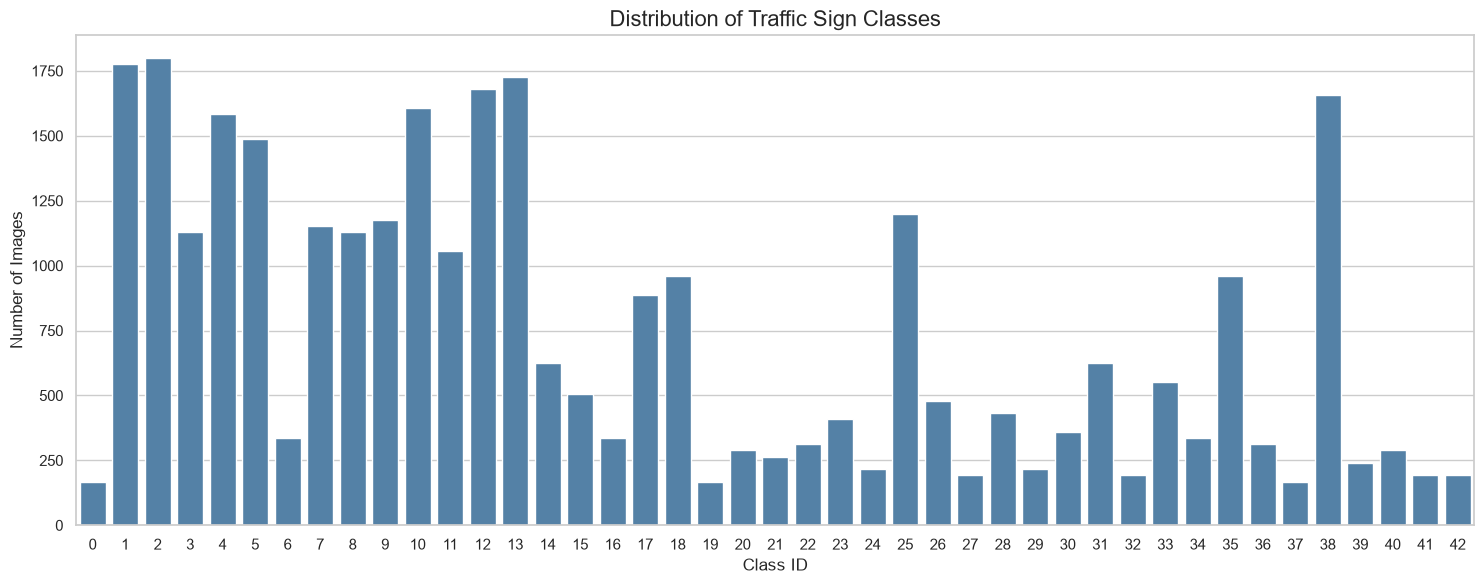

In [11]:

class_counts = train_split["ClassId"].value_counts().sort_index()

plt.figure(figsize=(15, 6))
sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    color="steelblue"
)

plt.title("Distribution of Traffic Sign Classes", fontsize=16)
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.xticks(range(43))
plt.tight_layout()

plt.savefig(
    EDA_DIR / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


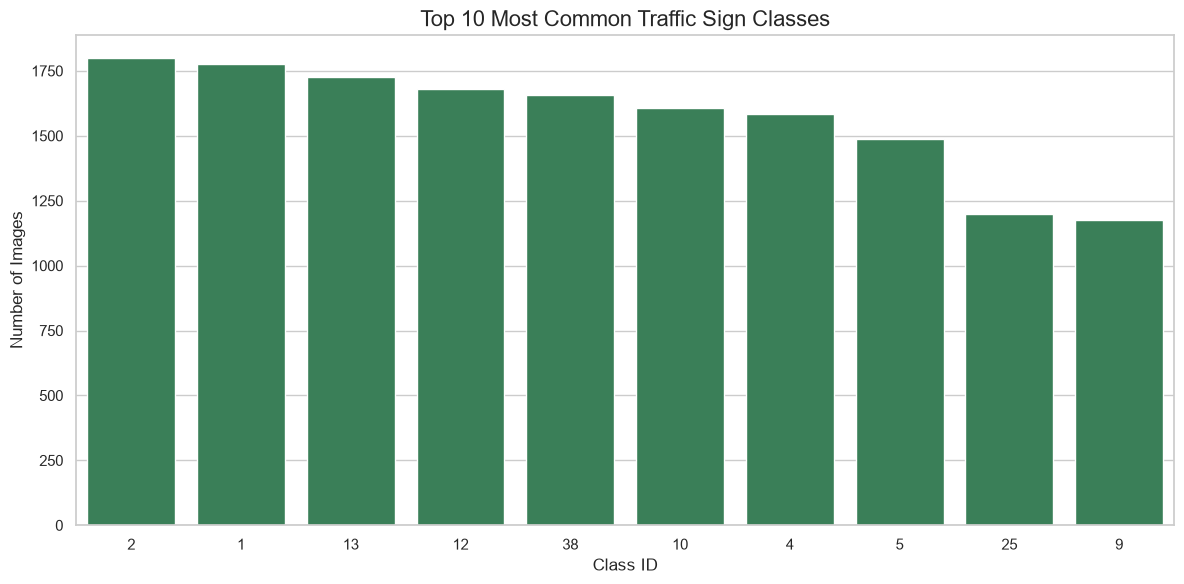

In [12]:

top_10 = class_counts.nlargest(10).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_10.index.astype(str),
    y=top_10.values,
    color="seagreen"
)

plt.title("Top 10 Most Common Traffic Sign Classes", fontsize=16)
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "02_most_common_classes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


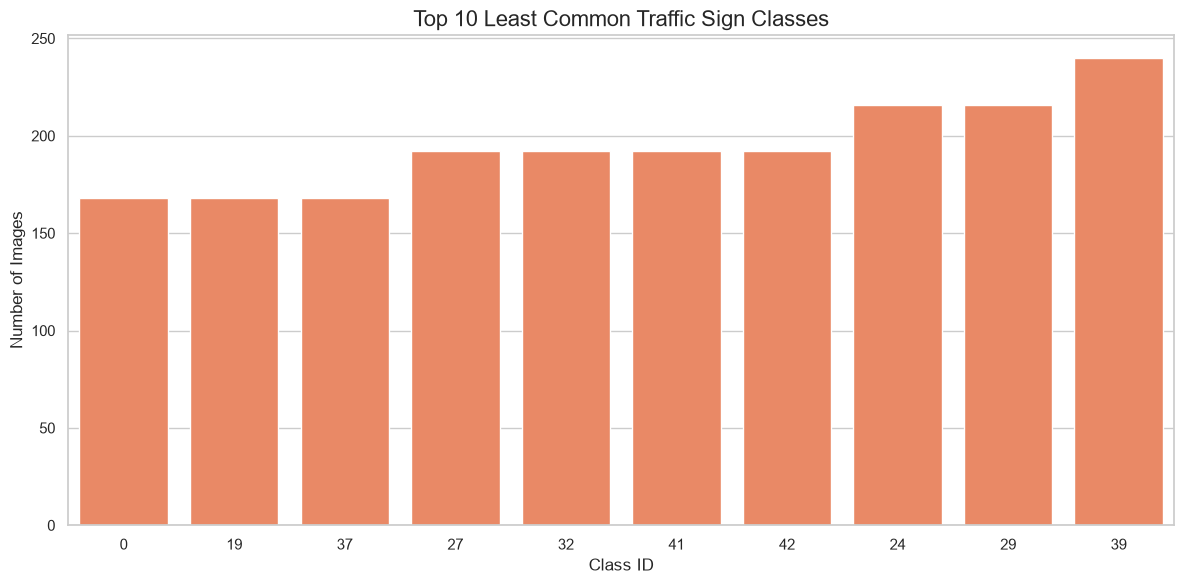

In [13]:

bottom_10 = class_counts.nsmallest(10).sort_values()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=bottom_10.index.astype(str),
    y=bottom_10.values,
    color="coral"
)

plt.title("Top 10 Least Common Traffic Sign Classes", fontsize=16)
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "03_least_common_classes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


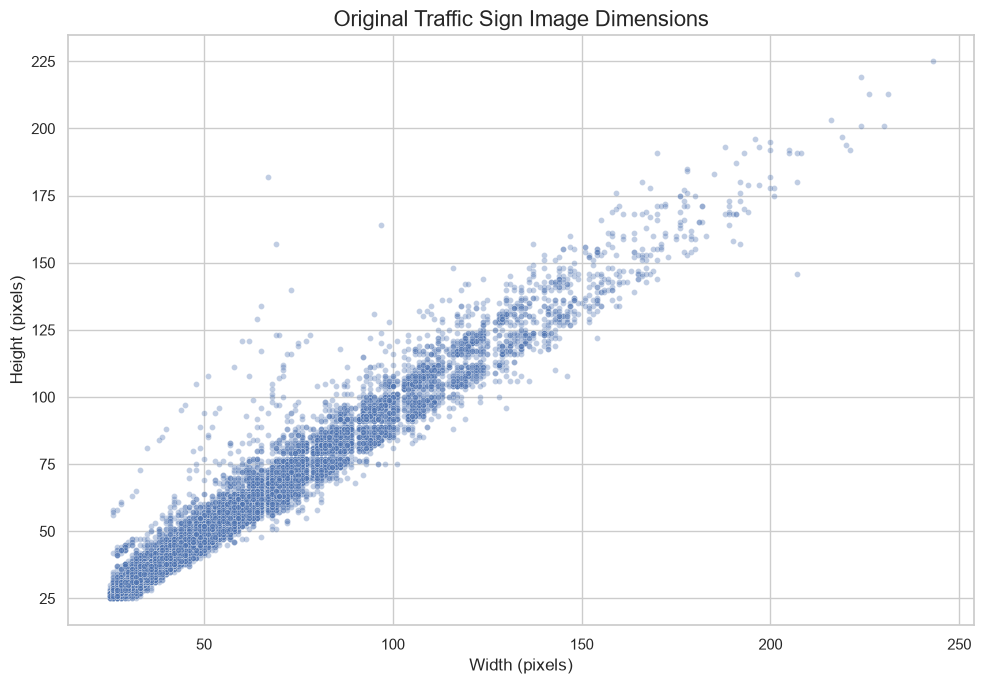

Image width summary:


count    31367.000000
mean        50.903402
std         24.400443
min         25.000000
25%         35.000000
50%         43.000000
75%         58.000000
max        243.000000
Name: Width, dtype: float64

Image height summary:


count    31367.000000
mean        50.384385
std         23.212132
min         25.000000
25%         35.000000
50%         43.000000
75%         58.000000
max        225.000000
Name: Height, dtype: float64

In [14]:

dimensions = train_split[["Width", "Height"]].copy()

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=dimensions,
    x="Width",
    y="Height",
    alpha=0.35,
    s=18
)

plt.title("Original Traffic Sign Image Dimensions", fontsize=16)
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "04_original_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Image width summary:")
display(train_split["Width"].describe())

print("Image height summary:")
display(train_split["Height"].describe())


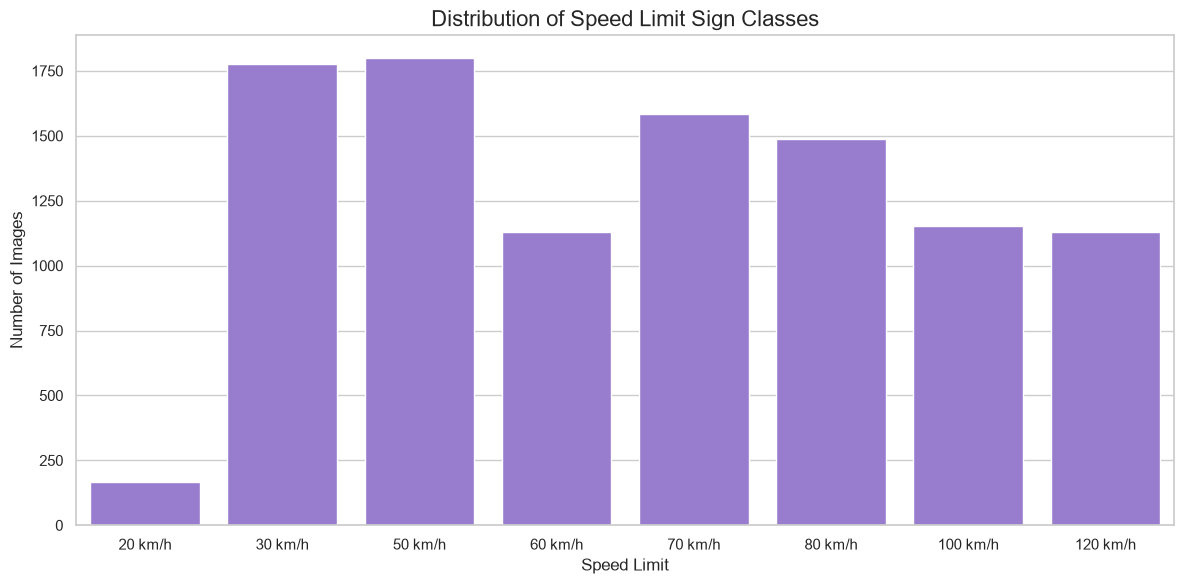

In [15]:

speed_limit_classes = [0, 1, 2, 3, 4, 5, 7, 8]

speed_limit_counts = (
    train_split[train_split["ClassId"].isin(speed_limit_classes)]
    ["ClassId"]
    .value_counts()
    .reindex(speed_limit_classes, fill_value=0)
)

speed_limit_labels = [
    "20 km/h",
    "30 km/h",
    "50 km/h",
    "60 km/h",
    "70 km/h",
    "80 km/h",
    "100 km/h",
    "120 km/h"
]

plt.figure(figsize=(12, 6))
sns.barplot(
    x=speed_limit_labels,
    y=speed_limit_counts.values,
    color="mediumpurple"
)

plt.title("Distribution of Speed Limit Sign Classes", fontsize=16)
plt.xlabel("Speed Limit")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "05_speed_limit_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


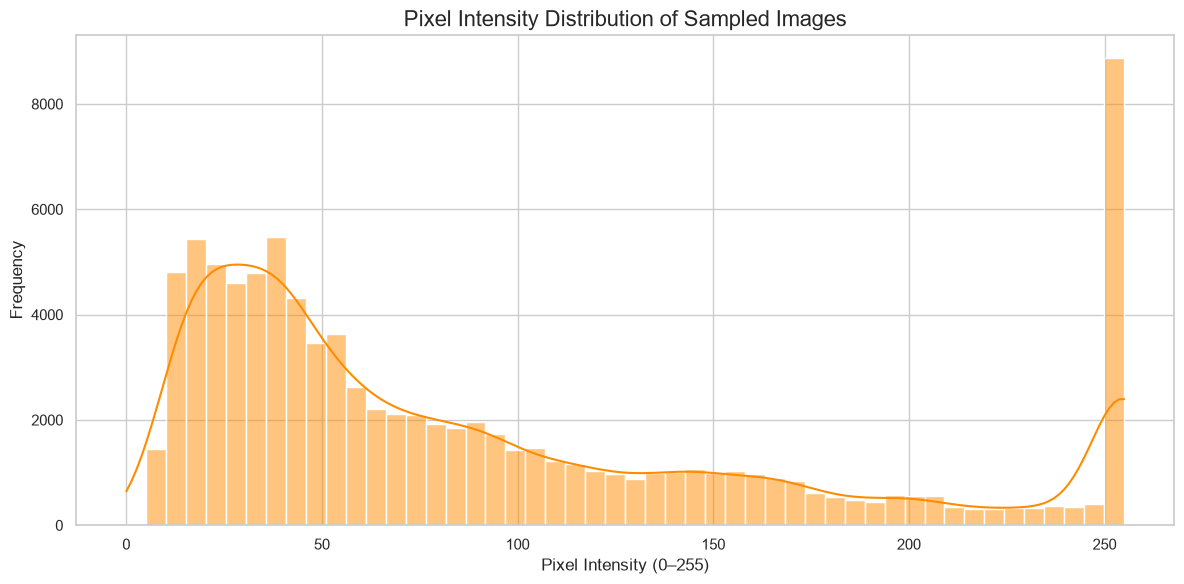

Number of sampled pixel values: 90716
Minimum intensity: 0
Maximum intensity: 255
Mean intensity: 91.27


In [16]:

sample_images = train_split.sample(
    n=min(100, len(train_split)),
    random_state=42
)

pixel_values = []

for image_path in sample_images["ImagePath"]:
    image = cv2.imread(image_path)

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        pixel_values.extend(image.flatten()[::10])

pixel_values = np.array(pixel_values)

plt.figure(figsize=(12, 6))
sns.histplot(
    pixel_values,
    bins=50,
    kde=True,
    color="darkorange"
)

plt.title("Pixel Intensity Distribution of Sampled Images", fontsize=16)
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    EDA_DIR / "06_pixel_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Number of sampled pixel values:", len(pixel_values))
print("Minimum intensity:", pixel_values.min())
print("Maximum intensity:", pixel_values.max())
print("Mean intensity:", round(pixel_values.mean(), 2))


In [17]:

print("SAVED EDA VISUALIZATIONS")
print("-" * 50)

for file in sorted(EDA_DIR.glob("*.png")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

print("\nTotal plots saved:", len(list(EDA_DIR.glob("*.png"))))


SAVED EDA VISUALIZATIONS
--------------------------------------------------
01_class_distribution.png | 129.03 KB
02_most_common_classes.png | 94.11 KB
03_least_common_classes.png | 89.84 KB
04_original_dimensions.png | 674.71 KB
05_speed_limit_comparison.png | 103.0 KB
06_pixel_distribution.png | 126.13 KB

Total plots saved: 6


In [18]:

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data directory:", PROCESSED_DIR)


Processed data directory: c:\Projects\Traffic_Sign_Recognition\data\processed


In [19]:

# Save training, validation, and test metadata
train_split.to_csv(
    PROCESSED_DIR / "train_metadata.csv",
    index=False
)

val_split.to_csv(
    PROCESSED_DIR / "validation_metadata.csv",
    index=False
)

test_split.to_csv(
    PROCESSED_DIR / "test_metadata.csv",
    index=False
)

# Save traffic sign class metadata
meta_clean.to_csv(
    PROCESSED_DIR / "class_metadata.csv",
    index=False
)

print("All metadata files saved successfully!")

for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")


All metadata files saved successfully!
class_metadata.csv | 1.05 KB
test_metadata.csv | 1256.59 KB
train_metadata.csv | 4078.07 KB
validation_metadata.csv | 1019.44 KB


In [20]:

import json

dataset_summary = {
    "dataset": "GTSRB - German Traffic Sign Recognition Benchmark",
    "dataset_source": "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    "number_of_classes": int(train_split["ClassId"].nunique()),
    "original_training_images": int(len(train_df)),
    "original_test_images": int(len(test_df)),
    "clean_training_images": int(len(train_clean)),
    "training_images": int(len(train_split)),
    "validation_images": int(len(val_split)),
    "test_images": int(len(test_split)),
    "random_state": 42,
    "validation_fraction": 0.20,
    "missing_training_image_paths": int(train_split["ImagePath"].isna().sum()),
    "missing_validation_image_paths": int(val_split["ImagePath"].isna().sum()),
    "missing_test_image_paths": int(test_split["ImagePath"].isna().sum()),
    "eda_plots_generated": int(len(list(EDA_DIR.glob("*.png"))))
}

summary_path = PROCESSED_DIR / "dataset_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(dataset_summary, file, indent=4)

print(json.dumps(dataset_summary, indent=4))
print("\nDataset summary saved:", summary_path)


{
    "dataset": "GTSRB - German Traffic Sign Recognition Benchmark",
    "dataset_source": "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    "number_of_classes": 43,
    "original_training_images": 39209,
    "original_test_images": 12630,
    "clean_training_images": 39209,
    "training_images": 31367,
    "validation_images": 7842,
    "test_images": 12630,
    "random_state": 42,
    "validation_fraction": 0.2,
    "missing_training_image_paths": 0,
    "missing_validation_image_paths": 0,
    "missing_test_image_paths": 0,
    "eda_plots_generated": 6
}

Dataset summary saved: c:\Projects\Traffic_Sign_Recognition\data\processed\dataset_summary.json


In [21]:

required_files = [
    "train_metadata.csv",
    "validation_metadata.csv",
    "test_metadata.csv",
    "class_metadata.csv",
    "dataset_summary.json"
]

print("PHASE 1 OUTPUT VERIFICATION")
print("=" * 45)

for filename in required_files:
    file_path = PROCESSED_DIR / filename
    print(
        f"{filename}:",
        "EXISTS" if file_path.exists() else "MISSING"
    )

print("\nEDA plots:", len(list(EDA_DIR.glob("*.png"))))

print("\nImage counts:")
print("Training:", len(train_split))
print("Validation:", len(val_split))
print("Testing:", len(test_split))

print("\nTotal:", len(train_split) + len(val_split) + len(test_split))


PHASE 1 OUTPUT VERIFICATION
train_metadata.csv: EXISTS
validation_metadata.csv: EXISTS
test_metadata.csv: EXISTS
class_metadata.csv: EXISTS
dataset_summary.json: EXISTS

EDA plots: 6

Image counts:
Training: 31367
Validation: 7842
Testing: 12630

Total: 51839
